# Atelier 1: Multiclass classification
Asmaa Atouailaa — FST Tanger

The goal is to predict a machine's `Failure Type` from its measurements and product type. There are six categories, including No Failure.

Dataset: [Predictive maintenance](https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification). Run the cells in order in Colab and upload `predictive_maintenance.csv`.

`Target` is excluded because it already indicates failure status. UDI and Product ID are identifiers and are also excluded.

In [1]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

csv_name = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df_cls = pd.read_csv(io.BytesIO(uploaded[csv_name]))

print("Shape:", df_cls.shape)
print("Columns:", df_cls.columns.tolist())
display(df_cls.head())

Saving predictive_maintenance.csv to predictive_maintenance.csv
Shape: (10000, 10)
Columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


## 1. Checking and exploring the data
The next cell checks missing values and duplicates, plots the measurements, and creates a 60% training, 20% validation and 20% test split. Stratification keeps similar class proportions in each set.

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64

Duplicate rows: 0

Failure categories:
Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


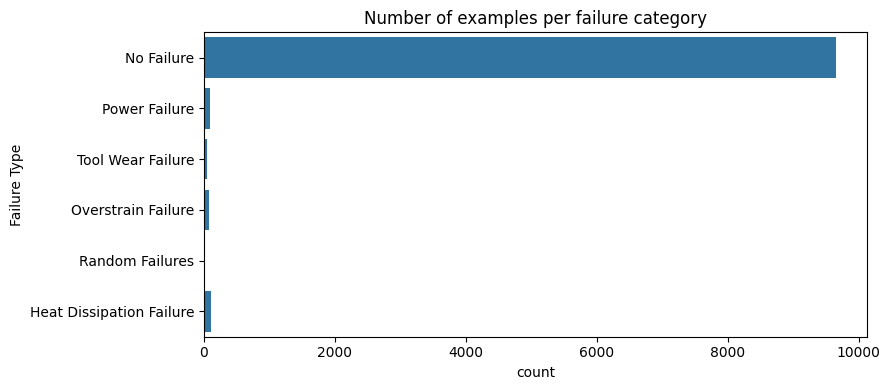

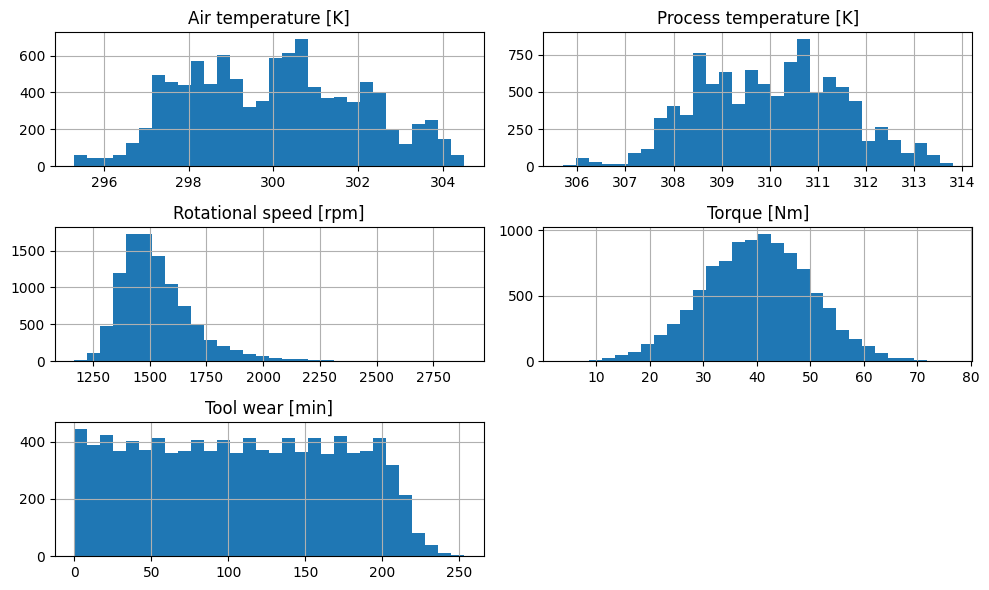

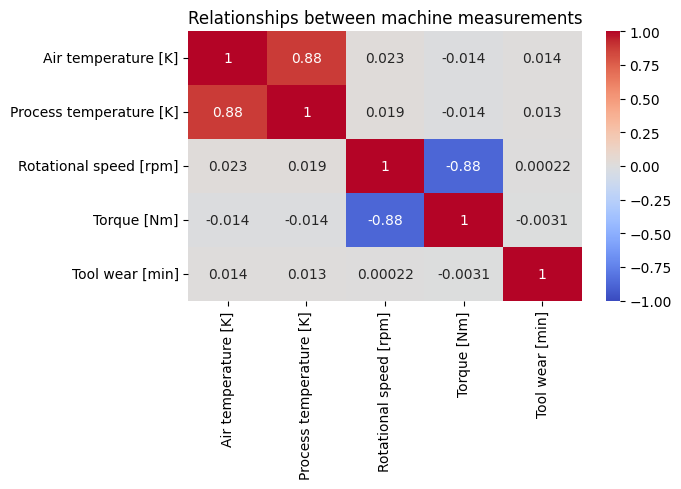


Training: (6000, 6)
Validation: (2000, 6)
Test: (2000, 6)
Category names: ['Heat Dissipation Failure' 'No Failure' 'Overstrain Failure'
 'Power Failure' 'Random Failures' 'Tool Wear Failure']


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

df_cls.columns = df_cls.columns.str.strip()

print("Missing values:")
print(df_cls.isna().sum())
print("\nDuplicate rows:", df_cls.duplicated().sum())

df_cls = df_cls.drop_duplicates().copy()
df_cls = df_cls.dropna(subset=["Failure Type"])

print("\nFailure categories:")
print(df_cls["Failure Type"].value_counts())

# Explore class imbalance
plt.figure(figsize=(9, 4))
sns.countplot(data=df_cls, y="Failure Type")
plt.title("Number of examples per failure category")
plt.tight_layout()
plt.show()

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df_cls[numeric_features].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(
    df_cls[numeric_features].corr(),
    annot=True, cmap="coolwarm", vmin=-1, vmax=1
)
plt.title("Relationships between machine measurements")
plt.tight_layout()
plt.show()

# Keep operating measurements and product type as inputs
X_cls = df_cls[numeric_features + ["Type"]].copy()

label_encoder = LabelEncoder()
y_cls = label_encoder.fit_transform(df_cls["Failure Type"])

# 60% training, 20% validation, 20% test
Xc_train, Xc_remaining, yc_train, yc_remaining = train_test_split(
    X_cls, y_cls,
    test_size=0.4,
    stratify=y_cls,
    random_state=42
)

Xc_val, Xc_test, yc_val, yc_test = train_test_split(
    Xc_remaining, yc_remaining,
    test_size=0.5,
    stratify=yc_remaining,
    random_state=42
)

print("\nTraining:", Xc_train.shape)
print("Validation:", Xc_val.shape)
print("Test:", Xc_test.shape)
print("Category names:", label_encoder.classes_)

### Observations
The table contains 10,000 rows. There are 9,652 No Failure cases but only 18 Random Failures cases. This is a large imbalance: a model can get high accuracy just by predicting No Failure.

Rotational speed is mostly near 1,500 rpm, and torque is concentrated around 40 Nm. The graphs help show the measurement ranges and relationships.

## 2. Scaling and balancing
Missing numerical values are filled with training medians, and numerical inputs are standardized. Product type is encoded as separate 0/1 columns. These steps learn their settings from training data only.

SMOTENC generates synthetic examples for the smaller training classes. Validation and test data are not balanced.

In [3]:
%pip -q install skorch imbalanced-learn

,Before,After
Heat Dissipation Failure,67,5791
No Failure,5791,5791
Overstrain Failure,47,5791
Power Failure,57,5791
Random Failures,11,5791
Tool Wear Failure,27,5791


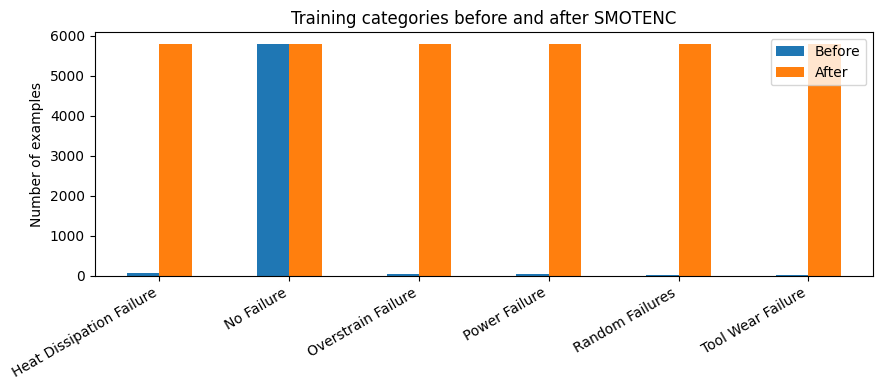

Balanced training shape: (34746, 8)


In [4]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTENC

# Fill missing numerical values using training medians
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

train_num = scaler.fit_transform(
    imputer.fit_transform(Xc_train[numeric_features])
)

val_num = scaler.transform(
    imputer.transform(Xc_val[numeric_features])
)

test_num = scaler.transform(
    imputer.transform(Xc_test[numeric_features])
)

# Keep product type categorical while generating examples
type_imputer = SimpleImputer(strategy="most_frequent")

train_type = type_imputer.fit_transform(Xc_train[["Type"]])
val_type = type_imputer.transform(Xc_val[["Type"]])
test_type = type_imputer.transform(Xc_test[["Type"]])

mixed_train = pd.DataFrame(train_num, columns=numeric_features)
mixed_train["Type"] = train_type.ravel()

smallest_class = pd.Series(yc_train).value_counts().min()

smote = SMOTENC(
    categorical_features=[5],
    k_neighbors=min(3, int(smallest_class) - 1),
    random_state=42
)

balanced_X, balanced_y = smote.fit_resample(
    mixed_train, yc_train
)

# Convert product types into separate 0/1 columns
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)
encoder.fit(train_type)

def encode_inputs(numbers, types):
    return np.column_stack([
        np.asarray(numbers, dtype="float32"),
        encoder.transform(np.asarray(types).reshape(-1, 1))
    ]).astype("float32")

Xc_train_ready = encode_inputs(train_num, train_type)
Xc_val_ready = encode_inputs(val_num, val_type)
Xc_test_ready = encode_inputs(test_num, test_type)

Xc_balanced = encode_inputs(
    balanced_X[numeric_features],
    balanced_X["Type"]
)

yc_balanced = np.asarray(balanced_y, dtype="int64")
yc_train = np.asarray(yc_train, dtype="int64")
yc_val = np.asarray(yc_val, dtype="int64")
yc_test = np.asarray(yc_test, dtype="int64")

counts = pd.DataFrame({
    "Before": pd.Series(yc_train).value_counts(),
    "After": pd.Series(yc_balanced).value_counts()
}).sort_index()

counts.index = label_encoder.inverse_transform(
    counts.index.to_numpy(dtype=int)
)

display(counts)

counts.plot.bar(figsize=(9, 4))
plt.title("Training categories before and after SMOTENC")
plt.ylabel("Number of examples")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("Balanced training shape:", Xc_balanced.shape)

### After balancing
Each training class has 5,791 examples, giving 34,746 rows and 8 encoded inputs. This balances the counts, but it does not create new real evidence. Random Failures still starts from only 11 original training examples.

## 3. Training and parameter search
The first network has 8 inputs, hidden layers of 32 and 16 neurons, and 6 output scores. It uses cross-entropy loss and Adam for 10 epochs.

The search compares four configurations on the original validation set. Hidden sizes 32 and 64 are tried with Adam/0.001/15 epochs and RMSprop/0.0005/20 epochs. This is a small grouped search, not every possible combination, so it cannot isolate each setting's effect. It uses one validation split.

Macro-F1 is used for selection because it gives the rare categories the same importance as No Failure.

In [5]:
import torch
from torch import nn

from skorch import NeuralNetClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import f1_score

torch.set_num_threads(2)

class FailureMLP(nn.Module):
    def __init__(self, hidden=32, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(Xc_balanced.shape[1], hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Linear(hidden // 2, len(label_encoder.classes_))
        )

    def forward(self, x):
        return self.layers(x)


def make_classifier(**settings):
    options = dict(
        module=FailureMLP,
        criterion=nn.CrossEntropyLoss,
        optimizer=torch.optim.Adam,
        lr=0.001,
        max_epochs=10,
        batch_size=256,
        train_split=None,
        iterator_train__shuffle=True,
        device="cpu",
        verbose=0
    )
    options.update(settings)
    return NeuralNetClassifier(**options)


# First model: keep it for the regularization comparison
torch.manual_seed(42)
initial_classifier = make_classifier()
initial_classifier.fit(Xc_balanced, yc_balanced)

print(
    "Initial validation macro-F1:",
    f1_score(
        yc_val,
        initial_classifier.predict(Xc_val_ready),
        average="macro",
        zero_division=0
    )
)

# Synthetic examples are training-only; validation stays original
Xs = np.concatenate([Xc_balanced, Xc_val_ready])
ys = np.concatenate([yc_balanced, yc_val])

validation_split = PredefinedSplit(
    np.concatenate([
        np.full(len(yc_balanced), -1),
        np.zeros(len(yc_val))
    ])
)

# Four selected configurations, rather than a large exhaustive grid
grid = [
    {
        "lr": [0.001],
        "module__hidden": [32, 64],
        "max_epochs": [15],
        "optimizer": [torch.optim.Adam]
    },
    {
        "lr": [0.0005],
        "module__hidden": [32, 64],
        "max_epochs": [20],
        "optimizer": [torch.optim.RMSprop]
    }
]

torch.manual_seed(42)

classification_search = GridSearchCV(
    make_classifier(),
    param_grid=grid,
    scoring="f1_macro",
    cv=validation_split,
    refit=False,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

classification_search.fit(Xs, ys)

print("Best settings:", classification_search.best_params_)
print("Best validation macro-F1:", classification_search.best_score_)

Initial validation macro-F1: 0.4231596270788624
Fitting 1 folds for each of 4 candidates, totalling 4 fits
[CV] END lr=0.001, max_epochs=15, module__hidden=32, optimizer=<class 'torch.optim.adam.Adam'>; total time=  10.6s
[CV] END lr=0.001, max_epochs=15, module__hidden=64, optimizer=<class 'torch.optim.adam.Adam'>; total time=   8.7s
[CV] END lr=0.0005, max_epochs=20, module__hidden=32, optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=  12.7s
[CV] END lr=0.0005, max_epochs=20, module__hidden=64, optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=  13.0s
Best settings: {'lr': 0.001, 'max_epochs': 15, 'module__hidden': 64, 'optimizer': <class 'torch.optim.adam.Adam'>}
Best validation macro-F1: 0.5015154279278282


## 4. Regularization comparison
The best search settings are Adam, learning rate 0.001, 15 epochs and hidden layers of 64 and 32 neurons. Search validation macro-F1 is 0.501515, compared with 0.423160 for the first model.

After fitting again, validation macro-F1 is 0.500670 for the tuned model, 0.445607 with dropout and 0.504783 with weight decay. Weight decay is selected from validation results. The difference from the tuned model is small and comes from one run.

In [6]:
settings = classification_search.best_params_.copy()

classifiers = {"Initial model": initial_classifier}

for name, extra in [
    ("Tuned model", {}),
    ("Dropout", {"module__dropout": 0.1}),
    ("Weight decay", {"optimizer__weight_decay": 0.0001})
]:
    torch.manual_seed(42)
    candidate = make_classifier(**{**settings, **extra})
    candidate.fit(Xc_balanced, yc_balanced)
    classifiers[name] = candidate
    print(name, "finished")

validation_rows = []

for name, candidate in classifiers.items():
    validation_rows.append({
        "Model": name,
        "Validation macro-F1": f1_score(
            yc_val,
            candidate.predict(Xc_val_ready),
            average="macro",
            zero_division=0
        )
    })

validation_results = pd.DataFrame(validation_rows).sort_values(
    "Validation macro-F1", ascending=False
)
display(validation_results)

chosen_name = validation_results.iloc[0]["Model"]
chosen_classifier = classifiers[chosen_name]
print("Selected using validation only:", chosen_name)

Tuned model finished
Dropout finished
Weight decay finished


,Model,Validation macro-F1
3,Weight decay,0.504783
1,Tuned model,0.500670
2,Dropout,0.445607
0,Initial model,0.423160


Selected using validation only: Weight decay


## 5. Curves and final evaluation
The selected configuration is trained again to record training/test loss and accuracy at each epoch. The settings and duration are fixed before viewing test results. Metrics use the original training examples, not the synthetic ones.

The reporting fit is a separate run, so its results may differ slightly. The test comparisons below are for reporting, not for selecting another model.

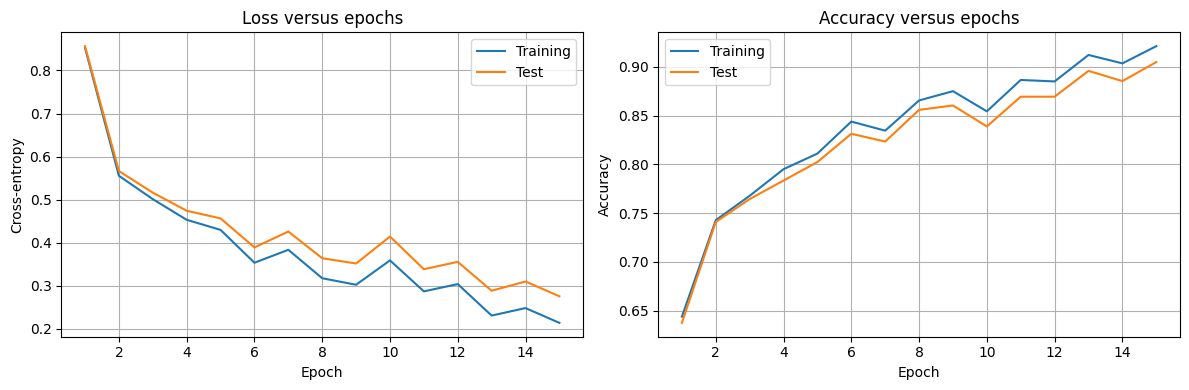

,Model,Dataset,Accuracy,Macro recall / sensitivity,Macro-F1
0,Initial model,Training,0.789000,0.925937,0.463195
1,Initial model,Test,0.781500,0.720959,0.432295
2,Tuned model,Training,0.908333,0.944707,0.556879
3,Tuned model,Test,0.893500,0.732201,0.507825
4,Dropout,Training,0.882500,0.943142,0.504332
5,Dropout,Test,0.864500,0.754310,0.459400
6,Weight decay,Training,0.910333,0.945053,0.557813
7,Weight decay,Test,0.893000,0.732114,0.503110
8,Selected configuration — reporting run,Training,0.921333,0.942376,0.564369
9,Selected configuration — reporting run,Test,0.905000,0.723857,0.502207



 Training
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.41      0.97      0.58        67
              No Failure       1.00      0.92      0.96      5791
      Overstrain Failure       0.53      0.87      0.66        47
           Power Failure       0.71      0.98      0.82        57
         Random Failures       0.06      0.91      0.12        11
       Tool Wear Failure       0.14      1.00      0.25        27

                accuracy                           0.92      6000
               macro avg       0.48      0.94      0.56      6000
            weighted avg       0.98      0.92      0.95      6000


 Test
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.34      1.00      0.51        23
              No Failure       1.00      0.91      0.95      1930
      Overstrain Failure       0.47      0.88      0.61        16
           Power Failure       0.68      0.89      0.7

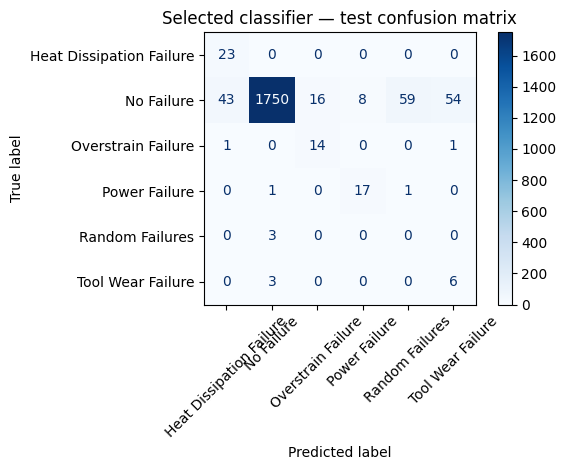

In [7]:
from sklearn.base import clone
from skorch.callbacks import Callback
from sklearn.metrics import (
    accuracy_score, recall_score, log_loss,
    classification_report, ConfusionMatrixDisplay
)

class ClassificationCurves(Callback):
    def on_train_begin(self, net, **kwargs):
        self.rows = []

    def on_epoch_end(self, net, **kwargs):
        row = {"Epoch": len(net.history)}

        # Measure original training examples, not synthetic examples
        for name, X, y in [
            ("Training", Xc_train_ready, yc_train),
            ("Test", Xc_test_ready, yc_test)
        ]:
            probabilities = net.predict_proba(X)
            predictions = probabilities.argmax(axis=1)

            row[f"{name} loss"] = log_loss(
                y, probabilities,
                labels=np.arange(len(label_encoder.classes_))
            )
            row[f"{name} accuracy"] = accuracy_score(y, predictions)

        self.rows.append(row)


# Fixed configuration: test curves are for reporting only
torch.manual_seed(42)
final_classifier = clone(chosen_classifier).set_params(
    callbacks=[("curves", ClassificationCurves())]
)
final_classifier.fit(Xc_balanced, yc_balanced)

curve_table = pd.DataFrame(
    dict(final_classifier.callbacks_)["curves"].rows
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name in ["Training", "Test"]:
    axes[0].plot(
        curve_table["Epoch"], curve_table[f"{name} loss"], label=name
    )
    axes[1].plot(
        curve_table["Epoch"], curve_table[f"{name} accuracy"], label=name
    )

axes[0].set(title="Loss versus epochs", ylabel="Cross-entropy")
axes[1].set(title="Accuracy versus epochs", ylabel="Accuracy")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

# Compare every fitted version; do not select again using test results
evaluation_models = {
    **classifiers,
    "Selected configuration — reporting run": final_classifier
}
metric_rows = []

for model_name, candidate in evaluation_models.items():
    for split_name, X, y in [
        ("Training", Xc_train_ready, yc_train),
        ("Test", Xc_test_ready, yc_test)
    ]:
        predictions = candidate.predict(X)
        metric_rows.append({
            "Model": model_name,
            "Dataset": split_name,
            "Accuracy": accuracy_score(y, predictions),
            "Macro recall / sensitivity": recall_score(
                y, predictions, average="macro", zero_division=0
            ),
            "Macro-F1": f1_score(
                y, predictions, average="macro", zero_division=0
            )
        })

classification_results = pd.DataFrame(metric_rows)
display(classification_results)

# Per-category results for the selected reporting model
for split_name, X, y in [
    ("Training", Xc_train_ready, yc_train),
    ("Test", Xc_test_ready, yc_test)
]:
    print("\n", split_name)
    print(classification_report(
        y,
        final_classifier.predict(X),
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    ))

ConfusionMatrixDisplay.from_predictions(
    yc_test,
    final_classifier.predict(Xc_test_ready),
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Selected classifier — test confusion matrix")
plt.tight_layout()
plt.show()

### Reading the results
Loss generally decreases and accuracy rises on both sets, with some fluctuations. In the reporting run, training accuracy is 92.13% and test accuracy is 90.5%. Macro-F1 is 0.564 on training and 0.502 on testing.

The confusion matrix shows 23/23 heat failures, 17/19 power failures and 6/9 tool wear failures detected. However, 180 healthy examples are labelled as a failure. All three Random Failures test cases are predicted as No Failure. Results for rare categories need caution because there are so few test examples.

## 6. Comparing with a simple baseline
The next cell compares the network with always predicting No Failure.

In [8]:
no_failure_label = label_encoder.transform(["No Failure"])[0]
baseline_predictions = np.full_like(yc_test, no_failure_label)

baseline_comparison = pd.DataFrame([
    {
        "Method": name,
        "Accuracy": accuracy_score(yc_test, predictions),
        "Macro recall": recall_score(
            yc_test, predictions, average="macro", zero_division=0
        ),
        "Macro-F1": f1_score(
            yc_test, predictions, average="macro", zero_division=0
        )
    }
    for name, predictions in [
        ("Always predict No Failure", baseline_predictions),
        ("Selected neural network",
         final_classifier.predict(Xc_test_ready))
    ]
])

display(baseline_comparison)

,Method,Accuracy,Macro recall,Macro-F1
0,Always predict No Failure,0.965,0.166667,0.163698
1,Selected neural network,0.905,0.723857,0.502207


### Conclusion
Always predicting No Failure gives **96.5% accuracy**, but detects no failure categories. The network has lower accuracy (**90.5%**) but higher macro recall (**72.4%**) and macro-F1 (**0.502**, versus **0.164** for the baseline).

The network recognizes several failure types, but false alarms and Random Failures remain problems. Synthetic balancing cannot replace more real examples. Without an otherwise identical unbalanced experiment, these results do not prove that augmentation improved performance.

### What I learned
I learned to prepare numerical and categorical inputs, balance only the training data, and compare model settings using validation data. The most useful lesson was that accuracy alone can be misleading. Recall, F1 and the confusion matrix show which categories the model actually detects.